# Image × Graduation × Replication

How does reusing a token's image relate to whether the token **graduates** (its bonding curve
completes)? Questions:

1. Do copies graduate more or less than originals, once launch period is controlled for?
2. Is it the image or the *win*? The same image, copied before vs after it graduated.
3. When are winners copied, and which copies succeed?
4. Does being copied hurt the original?
5. Creators: self-relaunch farms vs one-off launches.
6. Repeat winners: images that graduated more than once.
7. Near-duplicate *variants* (pHash) vs byte-identical copies.

**Definitions** (from `crypto_analysis.datalake.build_token_flags`). Tokens are ordered by
`tokens.created_at` within each image (`sha256`):

- **original**: the first token to use the image; **copy**: any later token with the same image.
- **self-relaunch**: a copy by the original's creator (`coin_creator`).
- **copy of a graduate**: a copy launched after a token with that image graduated.

**Outcome:** `grad_fast` = graduated **within 24 h of launch**. Graduation is fast (median ~10 min),
so the fixed window loses few graduates and removes the bias against recent launches, which had less
time to graduate. The crawl's last day is partial and is excluded with the day before it.

Rates are shown with 95% Wilson intervals. Everything is descriptive: the comparisons are associations,
not causal effects.

## Setup

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from crypto_analysis.datalake import build_token_flags, connect
from crypto_analysis.gallery import load_images, names_for, show_grid
from crypto_analysis.image_features import multi_index_pairs, star_clusters
from crypto_analysis.plotting import (
    COLORS,
    FIG_4x3,
    FIG_6x4,
    GOLD,
    RED_RAMP,
    ROLE_COLORS,
    ascii_label,
    count_label,
    density_area,
    dumbbell,
    forest,
    forest_by_row,
    format_date_axis,
    image_treemap,
    log_ticks,
    pct_label,
    percent_axis,
    rate_series,
    ridgeline,
    save_figure,
    set_latex_style,
    tex_escape,
    wilson_interval,
)

USE_TEX = set_latex_style()
warnings.filterwarnings("ignore", message="Glyph .* missing from font")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

In [2]:
FIG_DIR = Path("../reports/figures/02_image_graduation_replication")
SAVE_FIGS = True  # write every figure to FIG_DIR as PDF (for LaTeX) + PNG

# Output of `python -m crypto_analysis.compute_image_features` (colour stats + pHash per image)
FEATURES_DIR = Path("../data/image_features")

GRAD_WINDOW_HOURS = 24
SEED = 42

con = connect(threads=8, memory_limit="16GB")
build_token_flags(con, grad_window_hours=GRAD_WINDOW_HOURS)

# Keep only fully observed launch days: drop the partial last day and the one before it
con.execute('''
CREATE OR REPLACE TEMP VIEW tf AS
SELECT * FROM token_flags WHERE day < (SELECT max(day) - 1 FROM token_flags)
''')


def q(sql):
    return con.execute(sql).df()


BLUE, RED, AQUA = COLORS["blue"], COLORS["red"], COLORS["aqua"]
INK, INK_2, MUTED = COLORS["ink"], COLORS["ink_secondary"], COLORS["muted"]
DARK_GOLD = "#a86b00"


def save(fig, name):
    if SAVE_FIGS:
        save_figure(fig, FIG_DIR / name)


def rate_table(df, by, outcome="grad_fast", order=None):
    '''Graduation rate per group with its 95% (Wilson) interval.'''
    t = df.groupby(by, observed=True)[outcome].agg(k="sum", n="size")
    if order is not None:
        t = t.reindex(order)
    t["rate"] = t.k / t.n
    t["lo"], t["hi"] = wilson_interval(t.k, t.n)
    return t


PCT_TICKS = ([0.002, 0.005, 0.01, 0.02, 0.05, 0.1], ["0.2", "0.5", "1", "2", "5", "10"])



display(q("SELECT count(*) AS tokens, min(day) AS first_day, max(day) AS last_day FROM tf"))

,tokens,first_day,last_day
0,5114901,2025-10-26,2026-07-08


## 1. How fast do tokens graduate?

This sets the outcome window. Time from launch to graduation, for every graduated token.

,hours to graduate
0.25,0.03
0.50,0.16
0.75,1.07
0.90,28.18
0.95,215.31


Graduated within 24 h: 89.5% of graduates


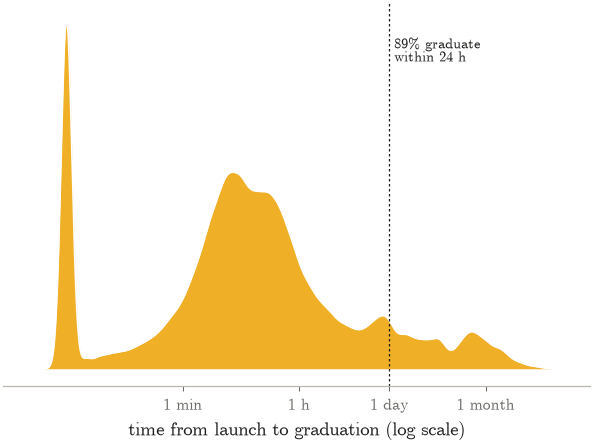

In [3]:
ttg_h = q("SELECT (grad_time - created_at) / 3600.0 AS h FROM token_flags WHERE graduated").h
display(ttg_h.quantile([0.25, 0.5, 0.75, 0.9, 0.95]).round(2).to_frame("hours to graduate"))
within_window = (ttg_h <= GRAD_WINDOW_HOURS).mean()
print(f"Graduated within {GRAD_WINDOW_HOURS} h: {within_window:.1%} of graduates")

fig, ax = plt.subplots(figsize=FIG_4x3)
grid, dens = density_area(ax, ttg_h.clip(lower=1 / 3600), log10=True, color=GOLD, bw=0.05, median=False)
x_window = np.log10(GRAD_WINDOW_HOURS)
ax.axvline(x_window, color=INK, lw=0.6, ls=(0, (2, 2)))
ax.text(x_window, dens.max() * 0.95, tex_escape(f" {within_window:.0%} graduate\n within {GRAD_WINDOW_HOURS} h"),
        fontsize=6.8, color=INK, va="top")
log_ticks(ax, "x", np.log10([1 / 60, 1, 24, 24 * 30]).tolist(), ["1 min", "1 h", "1 day", "1 month"])
ax.set_xlabel("time from launch to graduation (log scale)")
save(fig, "time_to_graduation")

**Cumulative graduation by role** (survival-analysis view). For tokens launched at least 30 days
before the end of the data (so every token is followed for 30 days), the share that has graduated
by each time since launch.

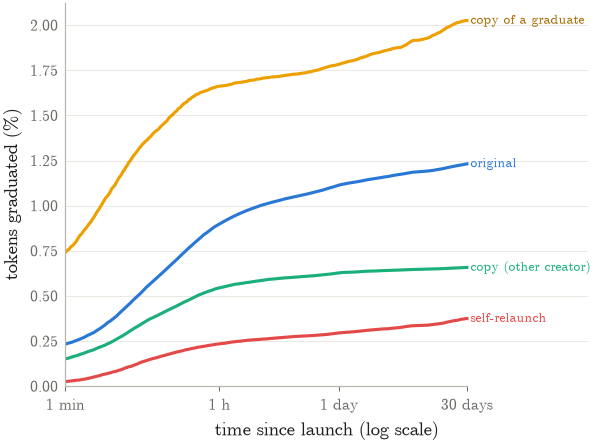

In [4]:
cum = q('''
SELECT role, CASE WHEN graduated THEN (grad_time - created_at) / 3600.0 END AS h
FROM token_flags
WHERE created_at <= (SELECT max(created_at) FROM token_flags) - 30 * 86400
''')
grid_h = np.logspace(np.log10(1 / 60), np.log10(24 * 30), 300)
fig, ax = plt.subplots(figsize=FIG_4x3)
for role in ROLE_COLORS:
    d = cum[cum.role == role]
    h = np.sort(d.h.dropna().to_numpy())
    share = np.searchsorted(h, grid_h, side="right") / len(d)
    ax.plot(grid_h, share, color=ROLE_COLORS[role], lw=1.5)
    ax.text(grid_h[-1] * 1.1, share[-1], tex_escape(role), fontsize=6.5, va="center",
            color=DARK_GOLD if role == "copy of a graduate" else ROLE_COLORS[role])
ax.set_xscale("log")
log_ticks(ax, "x", [1 / 60, 1, 24, 24 * 30], ["1 min", "1 h", "1 day", "30 days"])
ax.set_xlim(1 / 60, 24 * 30 * 25)
ax.spines["bottom"].set_bounds(1 / 60, 24 * 30)
ax.set_ylim(bottom=0)
percent_axis(ax)
ax.set_ylabel(pct_label("tokens graduated"))
ax.set_xlabel("time since launch (log scale)")
save(fig, "cumulative_graduation_by_role")

## 2. Roles and graduation, controlling for launch week

Graduation rates moved a lot over time (spikes in March and late June) and so did the mix of roles,
so raw rates can mislead. The **standardised** rate re-weights each role's weekly rates to the overall
weekly launch mix: what the role's rate would be if it had launched with the same timing as everyone.

In [5]:
ROLES = ["original", "self-relaunch", "copy (other creator)", "copy of a graduate"]
roles = q("SELECT role, date_trunc('week', day) AS week, grad_fast FROM tf")

raw = rate_table(roles, "role", order=ROLES)
weekly = roles.groupby(["role", "week"]).grad_fast.mean().rename("rate").reset_index()
week_mix = roles.week.value_counts(normalize=True).rename("w")
weekly = weekly.join(week_mix, on="week")
std = weekly.groupby("role").apply(lambda g: (g.rate * g.w).sum() / g.w.sum(), include_groups=False)

summary = raw[["n", "rate"]].assign(standardised=std.reindex(ROLES))
summary["share of tokens"] = summary.n / summary.n.sum()
display(summary.style.format({"n": "{:,}", "rate": "{:.2%}", "standardised": "{:.2%}",
                              "share of tokens": "{:.1%}"}))

,n,rate,standardised,share of tokens
role,,,,
original,"2,726,093",1.19%,1.24%,53.3%
self-relaunch,"881,607",0.32%,0.33%,17.2%
copy (other creator),"1,283,201",0.62%,0.62%,25.1%
copy of a graduate,"224,000",1.78%,1.92%,4.4%


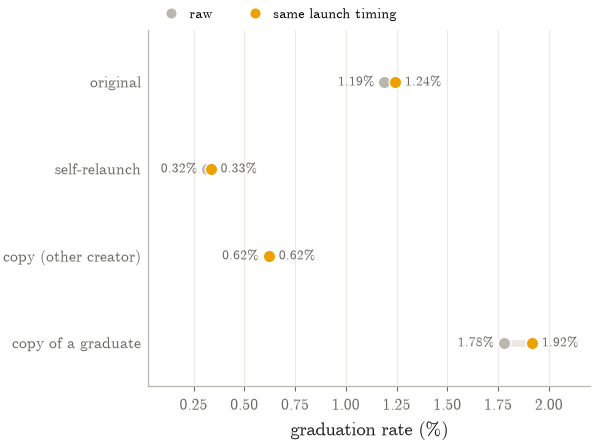

In [6]:
fig, ax = plt.subplots(figsize=FIG_4x3)
dumbbell(ax, ROLES, summary.rate.to_numpy(), summary.standardised.to_numpy(), left_label="raw",
         right_label="same launch timing", left_color=MUTED, right_color=GOLD)
ax.set_xlabel(pct_label("graduation rate"))
save(fig, "rate_by_role")

The same rates **week by week** (log scale), with 95% intervals as bands. Weeks with fewer than 200
tokens of a role are omitted.

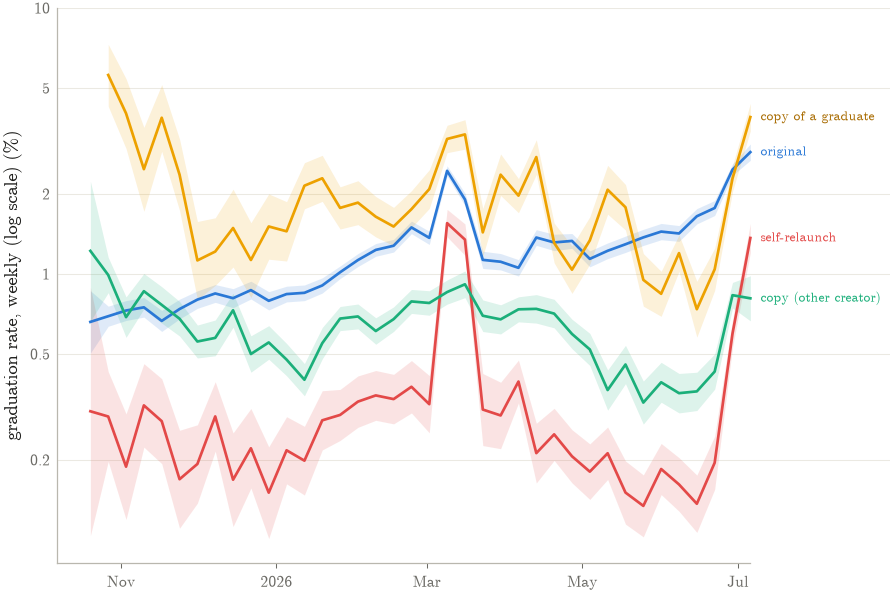

In [7]:
weekly = roles.groupby(["role", "week"]).grad_fast.agg(k="sum", n="size").reset_index()
fig, ax = plt.subplots(figsize=FIG_6x4)
for role in ROLES:
    d = weekly[(weekly.role == role) & (weekly.n >= 200)].sort_values("week")
    lo, hi = wilson_interval(d.k, d.n)
    w = pd.to_datetime(d.week)
    rate = d.k / d.n
    ax.fill_between(w, lo, hi, color=ROLE_COLORS[role], alpha=0.15, lw=0)
    ax.plot(w, rate, color=ROLE_COLORS[role], lw=1.3)
    ax.text(w.iloc[-1] + pd.Timedelta(days=4), rate.iloc[-1], tex_escape(role), fontsize=6.5, va="center",
            color=DARK_GOLD if role == "copy of a graduate" else ROLE_COLORS[role])
ax.set_yscale("log")
log_ticks(ax, "y", *PCT_TICKS)
last_week = pd.to_datetime(weekly.week).max()
ax.set_xlim(right=last_week + pd.Timedelta(days=55))
format_date_axis(ax)
ax.set_xticks([t for t in ax.get_xticks() if t <= plt.matplotlib.dates.date2num(last_week)])
ax.spines["bottom"].set_bounds(ax.get_xlim()[0], plt.matplotlib.dates.date2num(last_week))
ax.set_ylabel(pct_label("graduation rate, weekly (log scale)"))
save(fig, "rate_by_role_week")

## 3. Is it the image or the win?

Copies of a graduate might do well simply because the image is *good*. To separate the image from
the win, keep only images that **graduated at some point** and compare tokens using the *same*
image, launched **before** vs **after** its first graduation. The token(s) that graduated first are
excluded.

,k,n,rate,lo,hi
k,,,,,
original (did not graduate first),57,"11,902",0.48%,0.37%,0.62%
copy before the image graduated,235,"135,414",0.17%,0.15%,0.20%
copy after the image graduated,"3,984","224,166",1.78%,1.72%,1.83%


After vs before: 10.2x


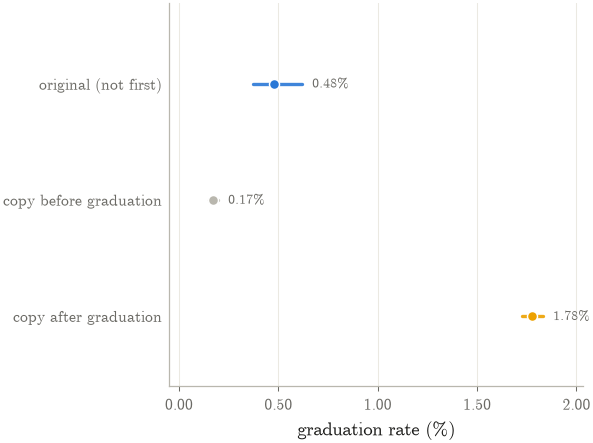

In [8]:
within = q('''
SELECT CASE WHEN NOT is_copy THEN 'original (did not graduate first)'
            WHEN created_at < first_grad THEN 'copy before the image graduated'
            ELSE 'copy after the image graduated' END AS k,
       grad_fast
FROM tf
WHERE first_grad IS NOT NULL AND coalesce(grad_time <> first_grad, true)
''')
WITHIN = ["original (did not graduate first)", "copy before the image graduated",
          "copy after the image graduated"]
within_t = rate_table(within, "k", order=WITHIN)
display(within_t.style.format({"k": "{:,}", "n": "{:,}", "rate": "{:.2%}", "lo": "{:.2%}", "hi": "{:.2%}"}))
print(f"After vs before: {within_t.rate.iloc[2] / within_t.rate.iloc[1]:.1f}x")

fig, ax = plt.subplots(figsize=FIG_4x3)
forest_by_row(ax, ["original (not first)", "copy before graduation", "copy after graduation"],
              within_t.k, within_t.n, [BLUE, MUTED, GOLD])
ax.set_xlabel(pct_label("graduation rate"))
save(fig, "same_image_before_after")

## 4. When are winners copied, and which copies succeed?

**Event study:** for every image that graduated (with at least 6 h of data before and 24 h after),
count the launches using it in 10-minute bins around its first graduation, averaged per image. The
graduating token itself is excluded, so the curve shows copies only.

47,020 graduated images
Copies per image: 1.66 in the 6 h before graduation, 2.60 in the 24 h after


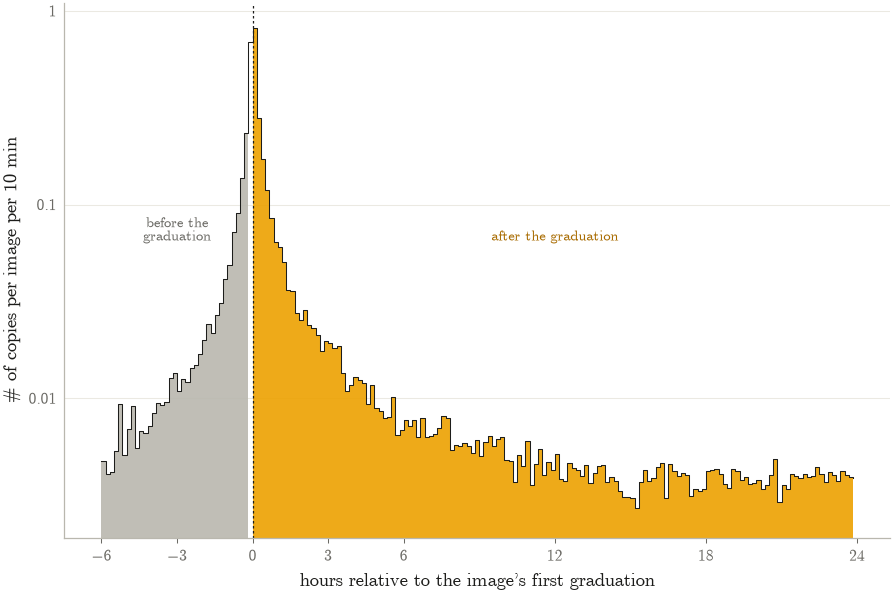

In [9]:
BIN_MIN = 10
event = q(f'''
WITH img AS (
    SELECT DISTINCT sha256, first_grad FROM tf
    WHERE first_grad BETWEEN (SELECT min(created_at) FROM tf) + 6 * 3600
                         AND (SELECT max(created_at) FROM tf) - 24 * 3600
)
SELECT floor((t.created_at - img.first_grad) / ({BIN_MIN} * 60)) * {BIN_MIN} / 60.0 AS h,
       count(*) / (SELECT count(*) FROM img) AS launches_per_image
FROM tf t JOIN img USING (sha256)
WHERE t.created_at - img.first_grad BETWEEN -6 * 3600 AND 24 * 3600 - 1
  AND coalesce(t.grad_time <> img.first_grad, true)
GROUP BY 1 ORDER BY 1
''')
n_images = q('''SELECT count(DISTINCT sha256) AS n FROM tf
                WHERE first_grad BETWEEN (SELECT min(created_at) FROM tf) + 6 * 3600
                                     AND (SELECT max(created_at) FROM tf) - 24 * 3600''').n[0]
print(f"{n_images:,} graduated images")
before = event.loc[event.h < 0, "launches_per_image"].sum()
after = event.loc[event.h >= 0, "launches_per_image"].sum()
print(f"Copies per image: {before:.2f} in the 6 h before graduation, {after:.2f} in the 24 h after")

fig, ax = plt.subplots(figsize=FIG_6x4)
floor = event.launches_per_image.min() * 0.7
pre, post = event[event.h < 0], event[event.h >= 0]
ax.fill_between(pre.h, floor, pre.launches_per_image, step="post", color=MUTED, alpha=0.9, lw=0)
ax.fill_between(post.h, floor, post.launches_per_image, step="post", color=GOLD, alpha=0.9, lw=0)
ax.step(event.h, event.launches_per_image, where="post", color=INK, lw=0.5)
ax.axvline(0, color=INK, lw=0.6, ls=(0, (2, 2)))
ax.text(-3, event.launches_per_image.max() * 0.08, "before the\ngraduation", ha="center", fontsize=7,
        color=INK_2)
ax.text(12, event.launches_per_image.max() * 0.08, "after the graduation", ha="center", fontsize=7,
        color=DARK_GOLD)
ax.set_yscale("log")
log_ticks(ax, "y", [0.001, 0.01, 0.1, 1], ["0.001", "0.01", "0.1", "1"])
ax.set_ylim(bottom=floor)
ax.set_xticks([-6, -3, 0, 3, 6, 12, 18, 24])
ax.set_xlabel("hours relative to the image's first graduation")
ax.set_ylabel(count_label(f"copies per image per {BIN_MIN} min"))
save(fig, "event_study")

,k,n,rate,lo,hi
delay,,,,,
< 10 min,441,"38,364",1.15%,1.05%,1.26%
10-60 min,933,"34,024",2.74%,2.57%,2.92%
1-6 h,766,"27,486",2.79%,2.60%,2.99%
6-24 h,606,"23,172",2.62%,2.42%,2.83%
1-7 days,666,"41,851",1.59%,1.48%,1.72%
> 7 days,571,"59,103",0.97%,0.89%,1.05%


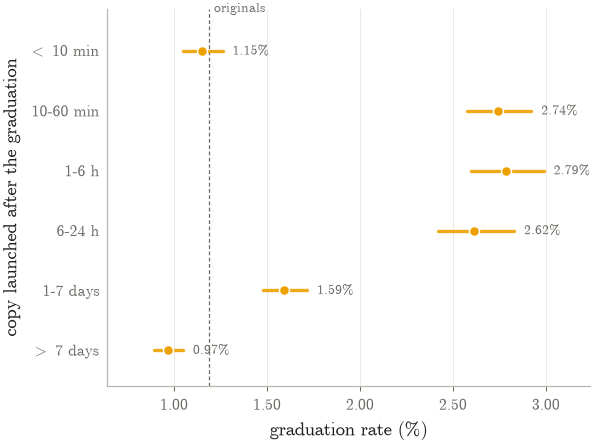

In [10]:
DELAYS = ["< 10 min", "10-60 min", "1-6 h", "6-24 h", "1-7 days", "> 7 days"]
copies = q('''
SELECT CASE WHEN secs_after_graduation < 600 THEN '< 10 min'
            WHEN secs_after_graduation < 3600 THEN '10-60 min'
            WHEN secs_after_graduation < 6 * 3600 THEN '1-6 h'
            WHEN secs_after_graduation < 86400 THEN '6-24 h'
            WHEN secs_after_graduation < 7 * 86400 THEN '1-7 days'
            ELSE '> 7 days' END AS delay,
       grad_fast
FROM tf WHERE copies_graduate
''')
delay_t = rate_table(copies, "delay", order=DELAYS)
original_rate = rate_table(roles, "role").loc["original", "rate"]
display(delay_t.style.format({"k": "{:,}", "n": "{:,}", "rate": "{:.2%}", "lo": "{:.2%}", "hi": "{:.2%}"}))

fig, ax = plt.subplots(figsize=FIG_4x3)
forest(ax, DELAYS, [rate_series("copies of a graduate", GOLD, delay_t.k, delay_t.n)], ref=original_rate,
       ref_label="originals")
ax.set_xlabel(pct_label("graduation rate"))
ax.set_ylabel("copy launched after the graduation")
save(fig, "copy_delay_rate")

**Copy waves.** For the 14 most-copied graduated images, the density of launches reusing the image
over time, centred on the image's first graduation (symmetric log scale). Grey is activity before
the graduation, gold after it; each ridge is scaled to its own peak.

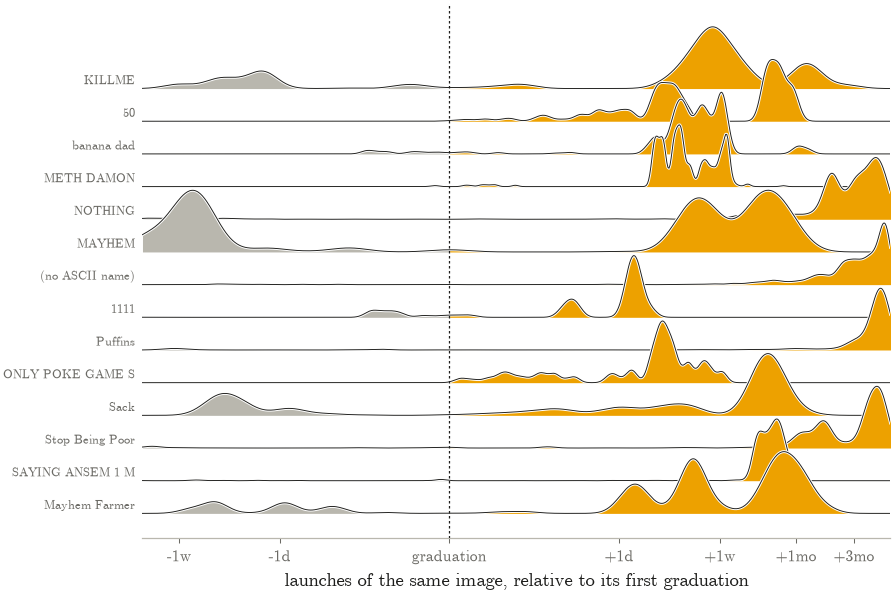

In [11]:
waves = q('''
WITH top AS (
    SELECT sha256, first_grad, count(*) FILTER (WHERE copies_graduate) AS n_copies
    FROM token_flags WHERE first_grad IS NOT NULL
    GROUP BY 1, 2 ORDER BY n_copies DESC LIMIT 14
)
SELECT t.sha256, (t.created_at - top.first_grad) / 3600.0 AS h, top.n_copies
FROM token_flags t JOIN top USING (sha256)
''')
order = waves.groupby("sha256").n_copies.first().sort_values(ascending=False).index
wave_names = names_for(con, order)


def symlog_hours(h):
    return np.sign(h) * np.log10(1 + np.abs(h))


fig, ax = plt.subplots(figsize=FIG_6x4)
ridgeline(ax, [(wave_names.get(s, ""), symlog_hours(waves.loc[waves.sha256 == s, "h"].to_numpy()))
               for s in order],
          np.linspace(symlog_hours(-24 * 14), symlog_hours(24 * 180), 700), split=0)
ticks = [-168, -24, 0, 24, 168, 720, 2160]
ax.set_xticks(symlog_hours(np.array(ticks)), ["-1w", "-1d", "graduation", "+1d", "+1w", "+1mo", "+3mo"])
ax.axvline(0, color=INK, lw=0.6, ls=(0, (2, 2)), zorder=100)
ax.set_xlabel("launches of the same image, relative to its first graduation")
save(fig, "copy_waves_ridgeline")

## 5. Does being copied hurt the original?

If copycats split the buyers, an original copied early should graduate *less*. Count the copies
launched within an original's **first 10 minutes**, among originals that had not graduated by then
(so the copies come strictly before the outcome).

,k,n,rate,lo,hi
early,,,,,
0,"12,395","2,387,885",0.52%,0.51%,0.53%
1,"1,414","198,359",0.71%,0.68%,0.75%
2-5,890,"88,091",1.01%,0.95%,1.08%
> 5,386,"34,451",1.12%,1.01%,1.24%


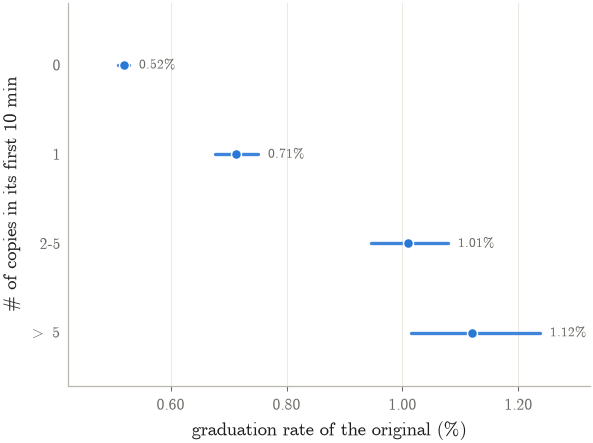

In [12]:
EARLY = ["0", "1", "2-5", "> 5"]
early = q('''
WITH o AS (
    SELECT mint, sha256, created_at, grad_fast FROM tf
    WHERE NOT is_copy AND (grad_time IS NULL OR grad_time - created_at > 600)
), c AS (
    SELECT sha256, created_at AS c_at FROM token_flags WHERE is_copy
), e AS (
    SELECT o.mint, count(c.c_at) FILTER (WHERE c.c_at - o.created_at <= 600) AS early_copies
    FROM o LEFT JOIN c USING (sha256) GROUP BY 1
)
SELECT CASE WHEN early_copies = 0 THEN '0' WHEN early_copies = 1 THEN '1'
            WHEN early_copies <= 5 THEN '2-5' ELSE '> 5' END AS early, grad_fast
FROM o JOIN e USING (mint)
''')
early_t = rate_table(early, "early", order=EARLY)
display(early_t.style.format({"k": "{:,}", "n": "{:,}", "rate": "{:.2%}", "lo": "{:.2%}", "hi": "{:.2%}"}))

fig, ax = plt.subplots(figsize=FIG_4x3)
forest(ax, EARLY, [rate_series("originals", BLUE, early_t.k, early_t.n)])
ax.set_xlabel(pct_label("graduation rate of the original"))
ax.set_ylabel(count_label("copies in its first 10 min"))
save(fig, "early_copies")

## 6. Creators: relaunch farms vs one-off launches

Two views: how many times a creator launched the **same image**, and how many tokens the creator
launched in total.

In [13]:
SAME = ["1", "2-5", "6-20", "> 20"]
SIZE = ["1", "2-10", "11-100", "> 100"]
creators = q('''
WITH ci AS (SELECT coin_creator, sha256, count(*) AS same_image FROM token_flags GROUP BY 1, 2),
     c AS (SELECT coin_creator, count(*) AS creator_tokens FROM token_flags GROUP BY 1)
SELECT t.coin_creator, t.role, ci.same_image, c.creator_tokens, t.grad_fast
FROM tf t JOIN ci USING (coin_creator, sha256) JOIN c USING (coin_creator)
''')
creators["same"] = pd.cut(creators.same_image, [0, 1, 5, 20, np.inf], labels=SAME)
creators["size"] = pd.cut(creators.creator_tokens, [0, 1, 10, 100, np.inf], labels=SIZE)
same_t = rate_table(creators, "same", order=SAME)
size_t = rate_table(creators, "size", order=SIZE)
size_t["creators"] = creators.groupby("size", observed=True).coin_creator.nunique().reindex(SIZE)
size_t["share of launches"] = size_t.n / size_t.n.sum()
fmt = {"k": "{:,}", "n": "{:,}", "creators": "{:,}", "rate": "{:.2%}", "lo": "{:.2%}", "hi": "{:.2%}",
       "share of launches": "{:.1%}"}
display(same_t.style.format(fmt))
display(size_t.style.format(fmt))

,k,n,rate,lo,hi
same,,,,,
1,"39,130","3,143,985",1.24%,1.23%,1.26%
2-5,"5,030","880,414",0.57%,0.56%,0.59%
6-20,"1,429","500,304",0.29%,0.27%,0.30%
> 20,"1,494","590,198",0.25%,0.24%,0.27%


,k,n,rate,lo,hi,creators,share of launches
size,,,,,,,
1,"16,506","965,079",1.71%,1.68%,1.74%,"965,079",18.9%
2-10,"11,520","862,396",1.34%,1.31%,1.36%,"243,693",16.9%
11-100,"7,716","1,191,102",0.65%,0.63%,0.66%,"45,961",23.3%
> 100,"11,341","2,096,324",0.54%,0.53%,0.55%,"5,015",41.0%


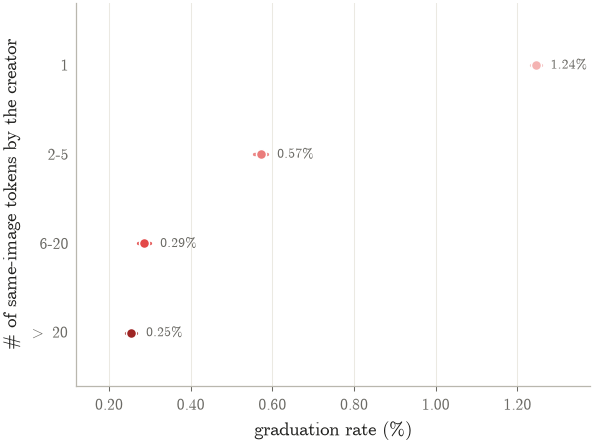

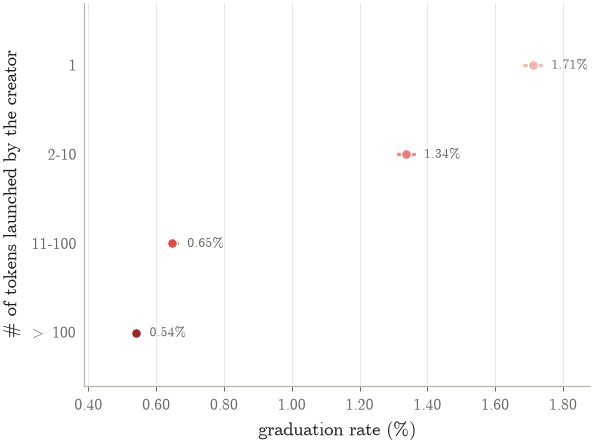

In [14]:
fig, ax = plt.subplots(figsize=FIG_4x3)
forest_by_row(ax, SAME, same_t.k, same_t.n, RED_RAMP)
ax.set_xlabel(pct_label("graduation rate"))
ax.set_ylabel(count_label("same-image tokens by the creator"))
save(fig, "creator_same_image")

fig, ax = plt.subplots(figsize=FIG_4x3)
forest_by_row(ax, SIZE, size_t.k, size_t.n, RED_RAMP)
ax.set_xlabel(pct_label("graduation rate"))
ax.set_ylabel(count_label("tokens launched by the creator"))
save(fig, "creator_size")

Creator size and role **together**: does copying a winner help farms as much as one-off creators?
One dot per role (95% interval, log scale); combinations with fewer than 500 tokens are omitted.

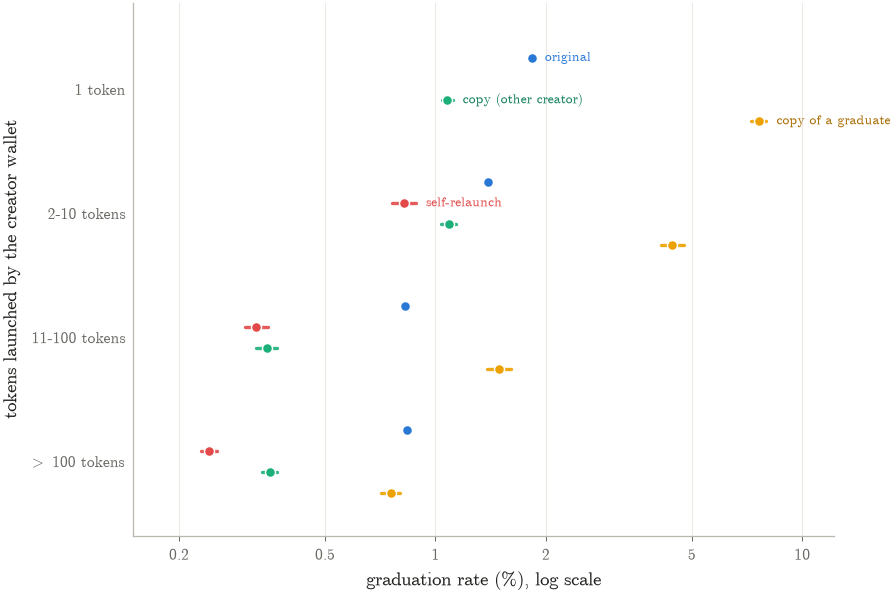

In [15]:
cells = creators.groupby(["size", "role"], observed=True).grad_fast.agg(k="sum", n="size")
series = []
for role in ROLES:
    t = cells.xs(role, level="role").reindex(SIZE)
    t.loc[t.n < 500, ["k", "n"]] = np.nan  # too few tokens for a stable estimate
    series.append(rate_series(role, ROLE_COLORS[role], t.k, t.n))

fig, ax = plt.subplots(figsize=FIG_6x4)
forest(ax, [f"{s} token" + ("" if s == "1" else "s") for s in SIZE], series, log=True, spacing=0.17)
log_ticks(ax, "x", *PCT_TICKS)
ax.set_xlabel(pct_label("graduation rate") + ", log scale")
ax.set_ylabel("tokens launched by the creator wallet")
save(fig, "rate_by_creator_size_and_role")

## 7. Repeat winners

Images that graduated more than once: the same artwork carried two or more tokens over the line.

,1,2,3,4,5,6,7,8,9,10+
images,45016,1981,451,187,92,46,24,14,12,54


,graduations,tokens,graduating_creators,name
0,106,270,2,Absolute Luck
1,77,560,3,X
2,51,502,11,They will call us lucky 1%
3,38,61,1,punchi
4,33,2706,1,50
5,31,162,1,"TO THE MOON, WHILE I SHIT"
6,30,81,1,dsf
7,29,79,9,Flying Apple
8,29,1824,22,
9,29,90,1,Elon pepe 67


Images that graduated more than once: 2,861 (6.0% of graduated images), carrying 8,235 graduations
... graduated by more than one creator: 69.5%


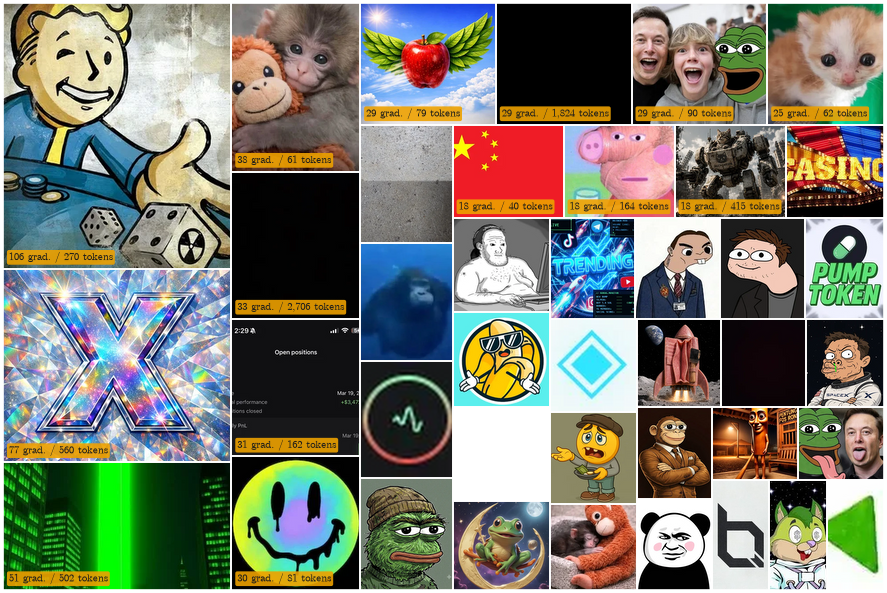

In [16]:
repeat = q('''
SELECT sha256, CAST(sum(graduated::INT) AS BIGINT) AS graduations, count(*) AS tokens,
       count(DISTINCT coin_creator) FILTER (WHERE graduated) AS graduating_creators
FROM token_flags GROUP BY 1 HAVING graduations > 0
''')
dist = repeat.graduations.clip(upper=10).value_counts().sort_index()
dist.index = [str(i) if i < 10 else "10+" for i in dist.index]
display(dist.to_frame("images").T)
display(repeat.nlargest(16, "graduations").assign(
    name=lambda d: d.sha256.map(names_for(con, d.sha256))).drop(columns="sha256").reset_index(drop=True))
multi = repeat[repeat.graduations > 1]
print(f"Images that graduated more than once: {len(multi):,} "
      f"({len(multi) / len(repeat):.1%} of graduated images), "
      f"carrying {multi.graduations.sum():,} graduations")
print(f"... graduated by more than one creator: {(multi.graduating_creators > 1).mean():.1%}")

top = repeat.nlargest(40, "graduations").reset_index(drop=True)
fig, ax = plt.subplots(figsize=FIG_6x4)
image_treemap(ax, load_images(con, top.sha256), top.sha256, top.graduations,
              badges=[f"{g} grad. / {t:,} tokens" for g, t in zip(top.graduations, top.tokens)],
              gold=[True] * len(top), min_badge_width=0.7)
save(fig, "repeat_winners")

## 8. Near-duplicate variants vs exact copies (pHash, all images)

Exact copies share the `sha256`. **Variants** are near-duplicates: a recolour, crop or re-save with
a different hash but a pHash within distance 4. Images are grouped with the same rules as notebook
01 (star clusters, low-contrast and flat-background images excluded since pHash is unreliable on
them), now over **every** stored image, using multi-index hashing for the pair search. Excluded
images keep their own `sha256` as their group.

Within each group, ordered by launch:

- **group original**: the first token in the group;
- **exact copy**: reuses an image (`sha256`) an earlier token already used;
- **variant**: a new `sha256`, but a near-duplicate of an earlier token's image.

Each is split by whether a token in the group had already graduated.

In [17]:
LOW_CONTRAST, FLAT_BACKGROUND, PHASH_MAX_DIST = 15, 0.8, 4

files = sorted(p for p in FEATURES_DIR.glob("shard_*.parquet") if not p.name.endswith(".errors.parquet"))
feat = pd.concat([pd.read_parquet(p, columns=["sha256", "phash", "contrast", "background_share"])
                  for p in files], ignore_index=True)
reliable = (feat.contrast >= LOW_CONTRAST) & (feat.background_share < FLAT_BACKGROUND)
print(f"{len(feat):,} images from {len(files)} shards; {reliable.mean():.1%} reliable for pHash")

hashes, inverse = np.unique(feat.loc[reliable, "phash"].to_numpy(np.uint64), return_inverse=True)
pairs = multi_index_pairs(hashes, PHASH_MAX_DIST)
centre = star_clusters(len(hashes), pairs.i, pairs.j)
print(f"{len(hashes):,} distinct reliable hashes, {len(pairs):,} pairs within distance {PHASH_MAX_DIST}")

feat["grp"] = feat.sha256
feat.loc[reliable, "grp"] = "p" + pd.Series(centre[inverse]).astype(str).to_numpy()
con.register("sha_group", feat[["sha256", "grp"]])

2,695,112 images from 270 shards; 89.5% reliable for pHash


1,920,995 distinct reliable hashes, 467,500 pairs within distance 4


In [18]:
con.execute('''
CREATE OR REPLACE TEMP TABLE token_groups AS
WITH g AS (
    SELECT t.mint, t.sha256, t.created_at, t.grad_time, t.grad_fast, t.is_copy, t.day, s.grp
    FROM token_flags t JOIN sha_group s USING (sha256)
), gs AS (
    SELECT grp, min(created_at) AS grp_first, min(grad_time) AS grp_first_grad,
           count(*) AS grp_tokens, count(DISTINCT sha256) AS grp_images
    FROM g GROUP BY 1
)
SELECT g.*, gs.grp_tokens, gs.grp_images,
       CASE WHEN g.created_at = gs.grp_first THEN 'group original'
            WHEN g.is_copy THEN 'exact copy'
            ELSE 'variant' END AS kind,
       coalesce(g.created_at > gs.grp_first_grad, false) AS after_group_graduation
FROM g JOIN gs USING (grp)
''')
cover = q("SELECT (SELECT count(*) FROM token_groups) AS grouped, (SELECT count(*) FROM token_flags) AS tokens")
print(f"Tokens with features: {cover.grouped[0]:,} of {cover.tokens[0]:,}")

shares = q('''
SELECT avg(CASE WHEN is_copy THEN 1 ELSE 0 END) AS copy_by_sha,
       avg(CASE WHEN kind <> 'group original' THEN 1 ELSE 0 END) AS copy_by_group,
       avg(CASE WHEN kind = 'variant' THEN 1 ELSE 0 END) AS variant
FROM token_groups
''').T.rename(columns={0: "share of tokens"})
display(shares.style.format("{:.1%}"))

Tokens with features: 5,141,193 of 5,141,193


,share of tokens
copy_by_sha,46.7%
copy_by_group,61.1%
variant,14.4%


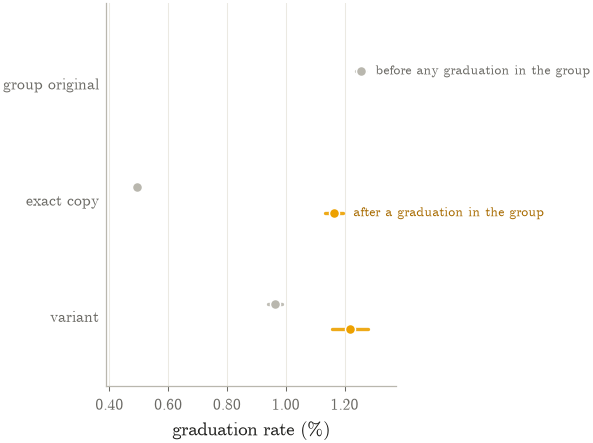

In [19]:
KINDS = ["group original", "exact copy", "variant"]
kinds = q(f'''SELECT kind, after_group_graduation, grad_fast FROM token_groups
              WHERE day < (SELECT max(day) - 1 FROM token_groups)''')
kind_t = rate_table(kinds, ["after_group_graduation", "kind"])
display(kind_t.style.format({"k": "{:,}", "n": "{:,}", "rate": "{:.2%}", "lo": "{:.2%}", "hi": "{:.2%}"}))

fig, ax = plt.subplots(figsize=FIG_4x3)
before_t = kind_t.loc[False].reindex(KINDS)
after_t = kind_t.loc[True].reindex(KINDS)
forest(ax, KINDS, [rate_series("before any graduation in the group", MUTED, before_t.k, before_t.n),
                   rate_series("after a graduation in the group", GOLD, after_t.k, after_t.n)], spacing=0.22)
ax.set_xlabel(pct_label("graduation rate"))
save(fig, "variants_vs_copies")

Groups where 2+ different variants graduated: 2,229


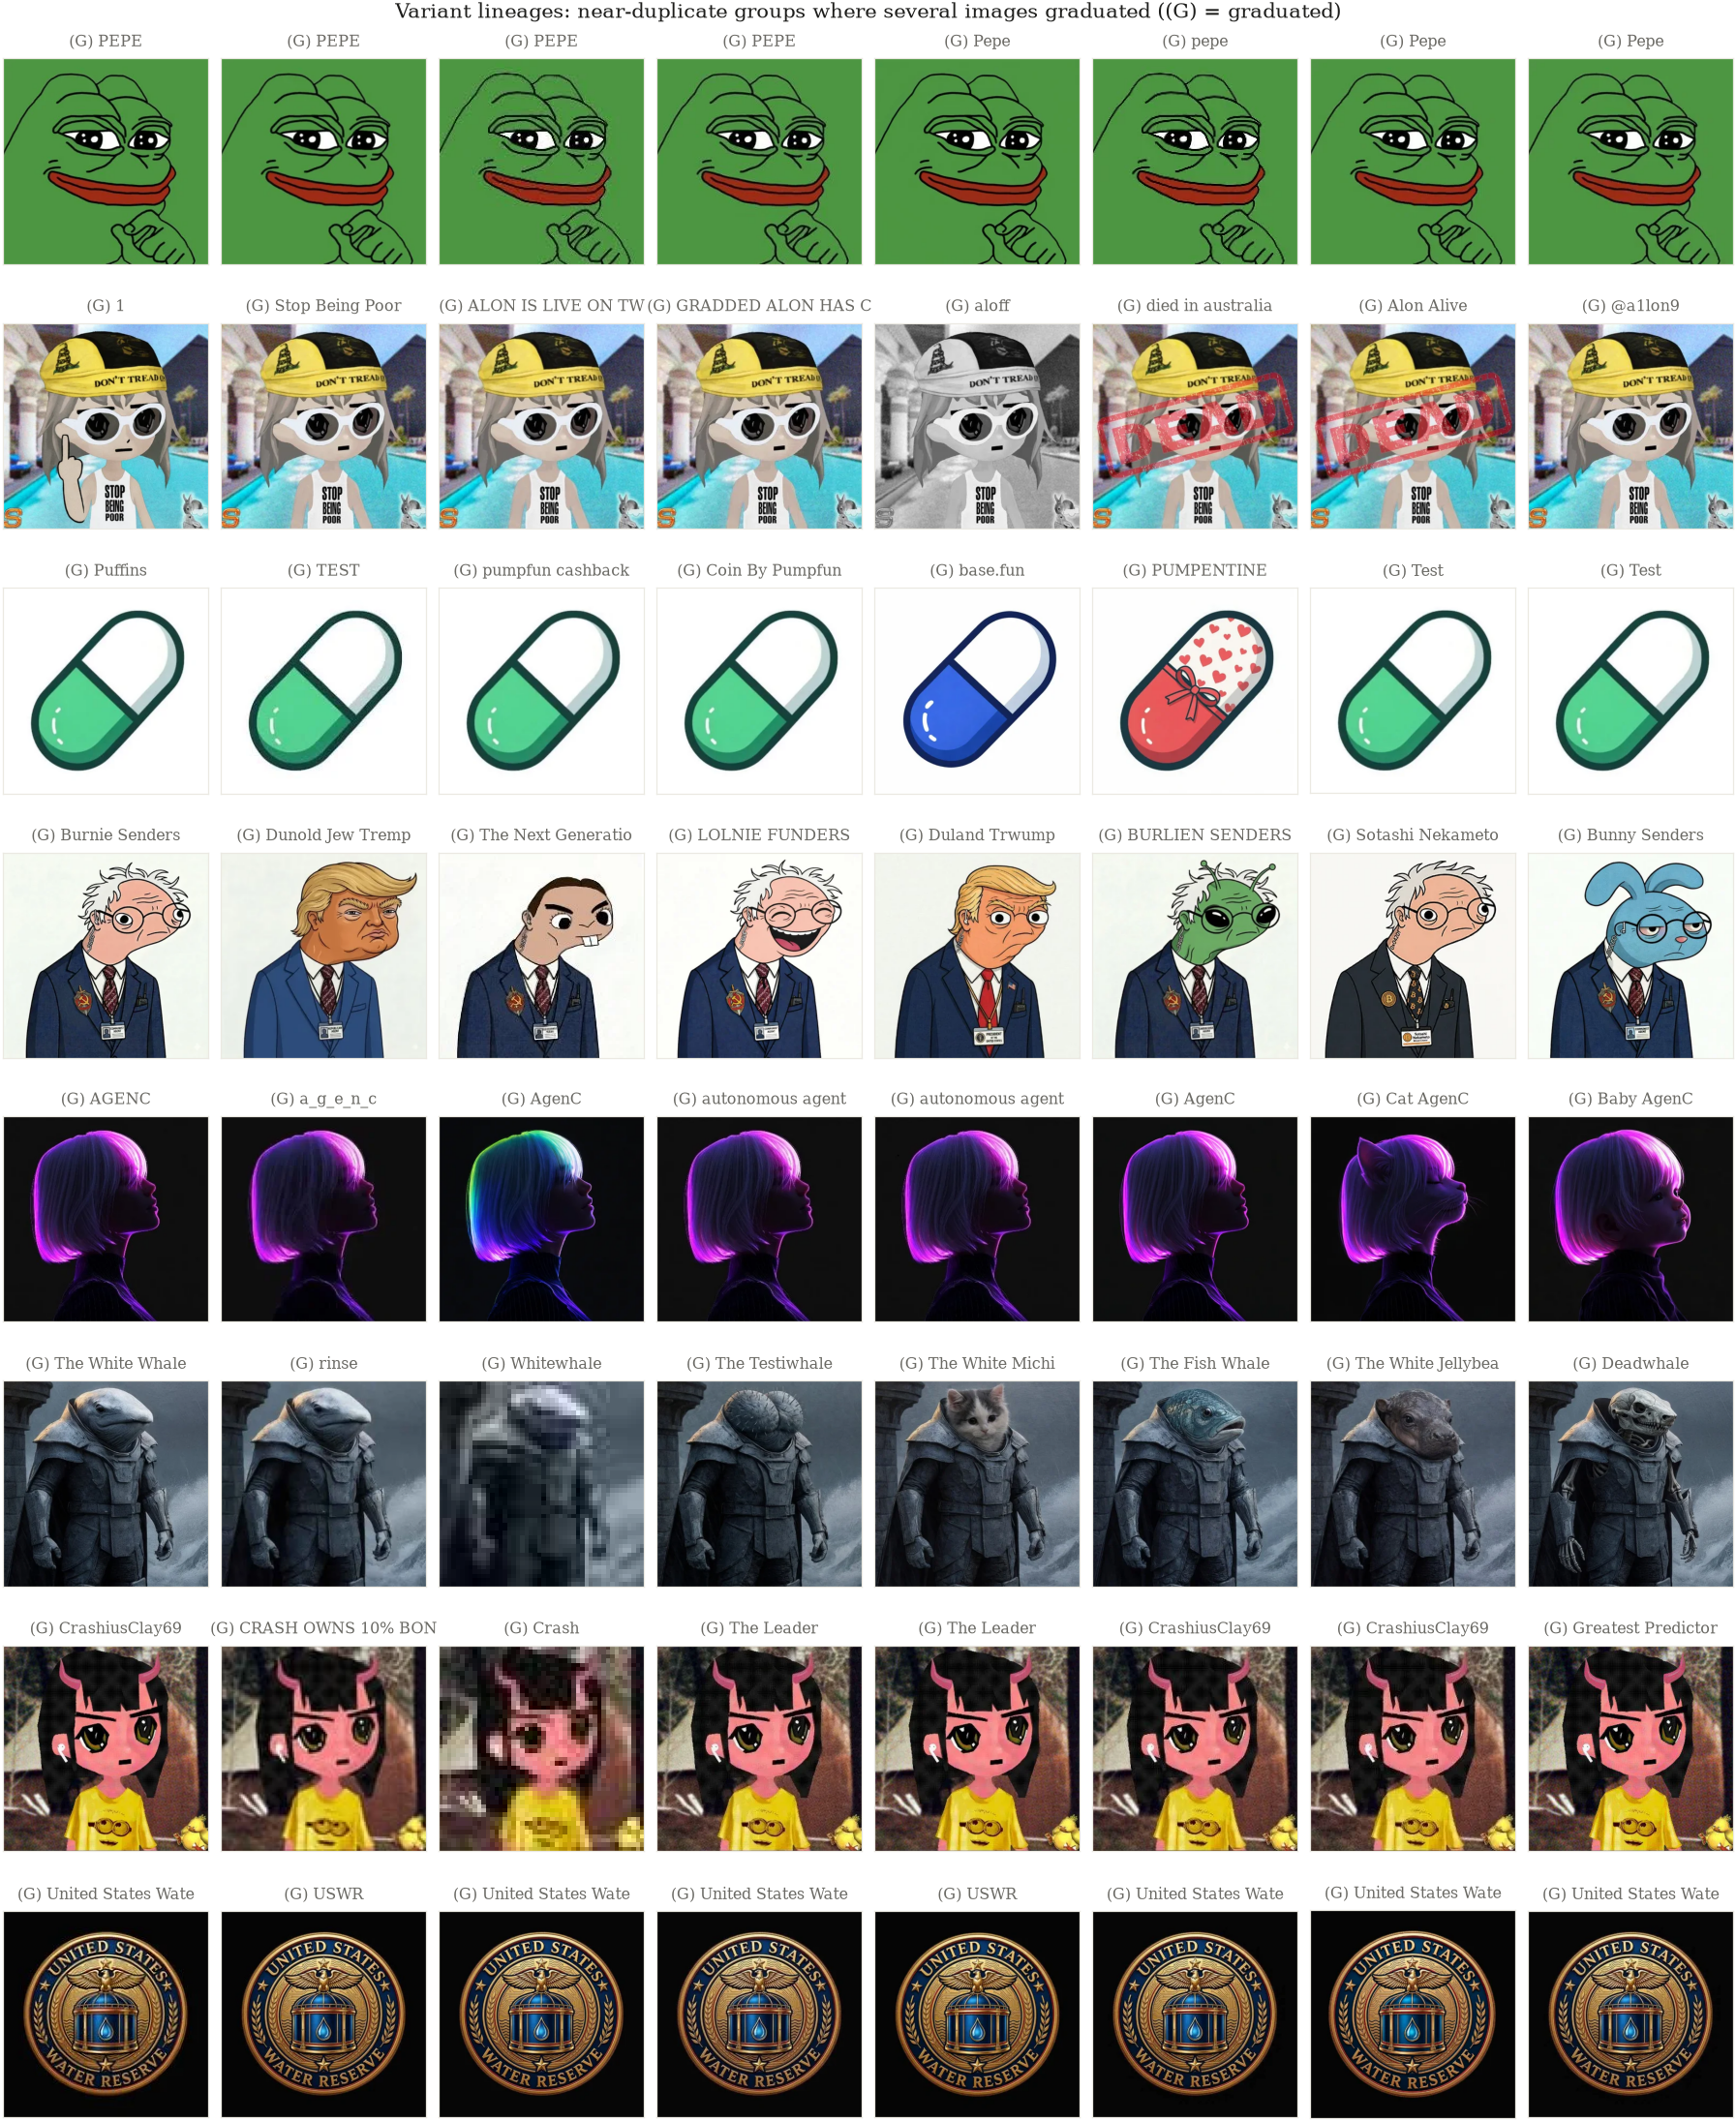

In [20]:
# Variant lineages: groups where several *different* images graduated
lineages = q('''
SELECT grp, count(DISTINCT sha256) FILTER (WHERE grad_time IS NOT NULL) AS graduated_images,
       count(*) FILTER (WHERE grad_time IS NOT NULL) AS graduations, max(grp_tokens) AS tokens
FROM token_groups WHERE grp LIKE 'p%'
GROUP BY 1 HAVING graduated_images > 1
ORDER BY graduated_images DESC, graduations DESC
''')
print(f"Groups where 2+ different variants graduated: {len(lineages):,}")

rows, titles = [], []
for g in lineages.grp.head(8):
    members = q(f'''SELECT sha256, min(created_at) AS first_use, bool_or(grad_time IS NOT NULL) AS grad
                    FROM token_groups WHERE grp = '{g}' GROUP BY 1 ORDER BY grad DESC, first_use LIMIT 8''')
    names = names_for(con, members.sha256)
    for r in members.itertuples():
        rows.append(r.sha256)
        titles.append(("(G) " if r.grad else "") + names.get(r.sha256, ""))
    rows += [None] * (8 - len(members))
    titles += [""] * (8 - len(members))
fig = show_grid(con, rows, titles, size=1.5,
                suptitle="Variant lineages: near-duplicate groups where several images graduated ((G) = graduated)")
save(fig, "variant_lineages")

**Lineage timelines.** The 15 near-duplicate groups where the most *different* variants graduated:
every launch in the group over time since the group's first launch (symmetric-log days). Grey ticks
are exact copies, blue ticks new variants, gold dots graduations. The number in brackets is how
many different variants of the group graduated.

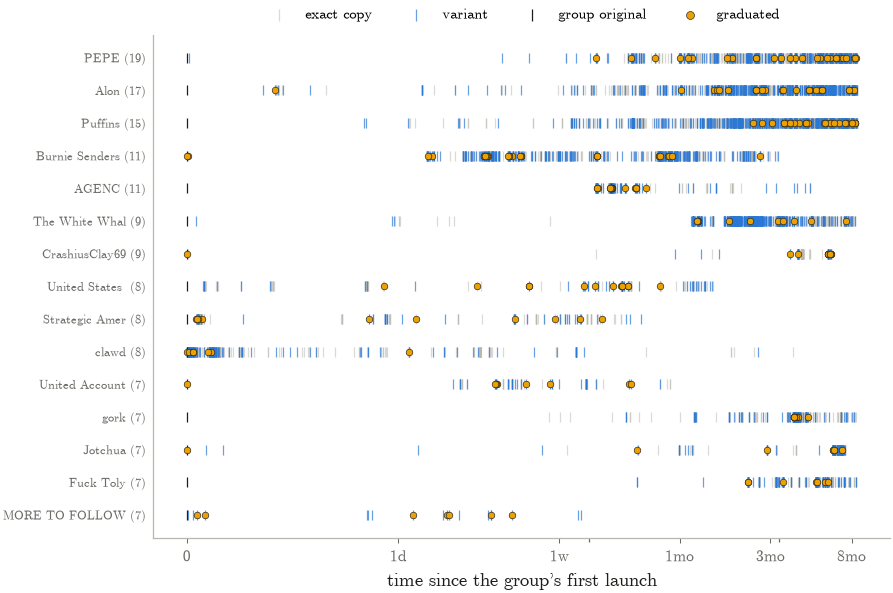

In [21]:
top_lin = lineages.head(15).reset_index(drop=True)
con.register("top_lin", top_lin[["grp"]])
lin = q('''
SELECT g.grp, g.sha256, g.kind, g.grad_time IS NOT NULL AS graduated,
       (g.created_at - min(g.created_at) OVER (PARTITION BY g.grp)) / 86400.0 AS days
FROM token_groups g JOIN top_lin USING (grp)
''')
lin["row"] = lin.grp.map(pd.Series(top_lin.index, index=top_lin.grp))
first_sha = lin.sort_values("days").groupby("grp").sha256.first()
lin_names = names_for(con, first_sha)

fig, ax = plt.subplots(figsize=FIG_6x4)
for kind, color, alpha in [("exact copy", MUTED, 0.5), ("variant", BLUE, 0.7),
                           ("group original", INK, 1.0)]:
    d = lin[lin.kind == kind]
    ax.scatter(d.days, d.row, marker="|", s=22, linewidths=0.6, color=color, alpha=alpha, label=kind)
d = lin[lin.graduated]
ax.scatter(d.days, d.row, s=10, color=GOLD, edgecolors=INK, linewidths=0.3, zorder=3, label="graduated")
ax.set_xscale("symlog", linthresh=1)
ax.set_xticks([0, 1, 7, 30, 90, 240], ["0", "1d", "1w", "1mo", "3mo", "8mo"])
labels = [f"{ascii_label(lin_names.get(first_sha[g], ''), 14)} ({n})"
          for g, n in zip(top_lin.grp, top_lin.graduated_images)]
ax.set_yticks(top_lin.index, labels, fontsize=6)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("time since the group's first launch")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=4, fontsize=7, markerscale=1.2)
save(fig, "lineage_timelines")

## 9. Takeaways

Numbers from the run on 2026-10-19 (launches 2025-10-26 → 2026-07-08, 5.11M tokens with an image).
"Graduation" means graduating within 24 h of launch.

1. **Graduation is fast.** Median ~10 min from launch, and 89.5% of graduates make it within 24 h,
   so the 24 h window loses little and makes every launch comparable.
2. **Copying a winner pays; recycling doesn't.** At the same launch timing (week-standardised),
   copies of a graduate graduate at 1.92%, originals at 1.24%, copies by other creators at 0.62%
   and self-relaunches at 0.33%. Standardising barely moves the rates, so the gap is not a timing
   artifact.
3. **It is the win, not the image.** For the *same* images, copies launched before the image's
   first graduation graduate at 0.17%; copies launched after it, at 1.78% (**10×**). A graduation is a
   public signal that copies ride on.
4. **Winners are copied immediately, and timing matters.** Copies cluster in the hour around the
   graduation, already rising before it (1.66 copies per image in the 6 h before, 2.60 in the
   24 h after). Copies launched 10 min–24 h after the graduation do best (2.6–2.8%, about 2× the
   originals). Copies within 10 min (likely sniping bots) and after a week (≈1%) don't.
5. **Being copied early marks attention, not harm.** Originals with more than 5 copies in their
   first 10 minutes graduate at 1.12%, against 0.52% with none. Copies follow promising tokens. The
   data can't say whether they also steal buyers.
6. **Relaunch farms are most of the volume and rarely graduate.** 5,015 creators with more than 100
   tokens each launched 41% of all tokens and graduate at 0.54%, against 1.71% for one-token creators.
   Relaunching the same image more than 20 times drops the rate to 0.25%. Copying a winner pays
   mostly for **small** creators: one-token creators copying a graduate graduate at **7.6%**
   (2–10 token creators 4.4%), while 100+ token farms copying a graduate reach only 0.8%.
7. **Repeat winners exist.** 2,861 images (6% of graduated images) graduated more than once,
   8,235 graduations in total, and 69.5% of them through different creators. One image graduated
   106 times.
8. **Variants are a large, hidden part of replication.** Counting pHash near-duplicates, 61.1% of
   tokens reuse earlier artwork (46.7% by exact hash), and 14.4% of tokens are variants. Before any
   graduation in their group, variants graduate about 2× as often as exact copies (0.96% vs 0.49%).
   Changing the image a little does better than reposting it. After a graduation both converge
   to ~1.2%. That is lower than the 1.78% for copies of the exact image in point 3, because a group
   "graduation" can come from a different variant. 2,229 groups have several *different* variants
   that graduated: meme templates re-drawn per narrative (Pepe, the "Stop Being Poor" character,
   the pill, politician caricatures on one template).

**Caveats.** Everything is observational. Graduation depends on trading activity this notebook does
not look at (`bonding_curve_trades`), so "copies of a graduate graduate more" can mean organic
attention or coordinated buying of copies. pHash groups exclude ~10% of images (flat backgrounds,
low contrast) where the hash is unreliable.

**Possible next steps:** bring in trades (time to graduation, number of distinct buyers, sniping
within the first blocks) to separate organic copycats from bot-run ones; model graduation with
role, timing, creator size and launch week together (logistic regression); and join the BERTopic
topics to see which narratives get copied and which copies win.